# Q2.3 LLM Variations with LoRA

Adapter-based fine-tuning of four 1-2B base LLMs (two monolingual, two multilingual) on BESSTIE sarcasm across three English varieties and three seeds.

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments,
)
from peft import LoraConfig, PeftModel, get_peft_model, TaskType
from sklearn.metrics import (
    f1_score, precision_score, recall_score, confusion_matrix, classification_report,
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

## Setup

In [2]:
RETRAIN = False

ADAPTER_ROOT = Path("./adapter_outputs")
EVAL_ROOT = Path("./eval_outputs")

BASES = {
    "Llama-3.2-1B":   "meta-llama/Llama-3.2-1B",
    "Qwen2.5-1.5B":   "Qwen/Qwen2.5-1.5B",
    "SmolLM2-1.7B":   "HuggingFaceTB/SmolLM2-1.7B",
    "OLMo-2-0425-1B": "allenai/OLMo-2-0425-1B",
}
VARIETIES = ["en-UK", "en-AU", "en-IN"]
SEEDS = [42, 123, 2024]

LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.1
TARGET_MODULES = ["q_proj", "v_proj"]
LR = 2e-4
EPOCHS = 3
BATCH_SIZE = 16
EVAL_BATCH = 32
MAX_LEN = 256

## Training (gated)

Default off. Set `RETRAIN=True` to re-train all 36 adapters and re-run the cross-variety evaluation on a GPU.

In [3]:
if RETRAIN:
    DATASET_NAME = "surrey-nlp/BESSTIE-CW-26"

    def load_besstie():
        return load_dataset(DATASET_NAME)

    def slice_for_variety(ds, variety):
        out = {}
        for split in ["train", "validation", "test"]:
            out[split] = ds[split].filter(lambda x: x["variety"] == variety)
        return out

    class WeightedTrainer(Trainer):
        def __init__(self, *args, class_weights=None, **kwargs):
            super().__init__(*args, **kwargs)
            self.class_weights = class_weights

        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop('labels')
            outputs = model(**inputs)
            logits = outputs.logits
            loss_fn = nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device))
            loss = loss_fn(logits.view(-1, logits.size(-1)), labels.view(-1))
            return (loss, outputs) if return_outputs else loss

    def predict_with(model, tok, dataset):
        eval_args = TrainingArguments(output_dir="/tmp/eval_state",
                                      per_device_eval_batch_size=EVAL_BATCH,
                                      report_to='none', bf16=True)
        coll = DataCollatorWithPadding(tokenizer=tok)
        tr = Trainer(model=model, args=eval_args, data_collator=coll)
        out = tr.predict(dataset)
        preds = np.argmax(out.predictions, axis=-1)
        return preds, np.array(dataset['labels'])

    ds = load_besstie()
    rows = []
    for base_short, base_id in BASES.items():
        tok = AutoTokenizer.from_pretrained(base_id)
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token

        def preprocess(batch):
            out = tok(batch['text'], truncation=True, max_length=MAX_LEN)
            out['labels'] = [int(x) for x in batch['Sarcasm']]
            return out

        for variety in VARIETIES:
            split = slice_for_variety(ds, variety)
            train_labels = np.array(split['train']['Sarcasm']).astype(int)
            class_weights = torch.tensor(
                compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels),
                dtype=torch.float32)
            train_tok = split['train'].map(preprocess, batched=True)
            val_tok = split['validation'].map(preprocess, batched=True)
            test_tok = split['test'].map(preprocess, batched=True)
            keep = ['input_ids', 'attention_mask', 'labels']
            train_tok = train_tok.remove_columns([c for c in train_tok.column_names if c not in keep])
            val_tok = val_tok.remove_columns([c for c in val_tok.column_names if c not in keep])
            test_tok = test_tok.remove_columns([c for c in test_tok.column_names if c not in keep])
            collator = DataCollatorWithPadding(tokenizer=tok)

            for seed in SEEDS:
                torch.manual_seed(seed)
                np.random.seed(seed)
                run_tag = f"{base_short}_{variety}_seed{seed}"
                out_dir = ADAPTER_ROOT / run_tag
                out_dir.mkdir(parents=True, exist_ok=True)

                model = AutoModelForSequenceClassification.from_pretrained(base_id, num_labels=2)
                model.config.pad_token_id = tok.pad_token_id
                lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                      target_modules=TARGET_MODULES, task_type=TaskType.SEQ_CLS)
                model = get_peft_model(model, lora_cfg)

                args = TrainingArguments(output_dir=str(out_dir / 'trainer_state'),
                                         num_train_epochs=EPOCHS,
                                         per_device_train_batch_size=BATCH_SIZE,
                                         per_device_eval_batch_size=BATCH_SIZE,
                                         learning_rate=LR, eval_strategy='epoch',
                                         save_strategy='no', logging_steps=50,
                                         seed=seed, report_to='none', bf16=True)
                trainer = WeightedTrainer(model=model, args=args,
                                          train_dataset=train_tok, eval_dataset=val_tok,
                                          data_collator=collator, class_weights=class_weights)
                trainer.train()
                model.save_pretrained(out_dir / 'adapter')

                model_eval = PeftModel.from_pretrained(
                    AutoModelForSequenceClassification.from_pretrained(base_id, num_labels=2).to('cuda'),
                    out_dir / 'adapter').eval()
                for test_var in VARIETIES:
                    for sp_name, sp_data in [('val', val_tok if test_var == variety else slice_for_variety(ds, test_var)['validation'].map(preprocess, batched=True)),
                                              ('test', test_tok if test_var == variety else slice_for_variety(ds, test_var)['test'].map(preprocess, batched=True))]:
                        sp_data = sp_data.remove_columns([c for c in sp_data.column_names if c not in keep])
                        preds, y = predict_with(model_eval, tok, sp_data)
                        rows.append({'base_short': base_short, 'train_var': variety, 'test_var': test_var,
                                     'split': sp_name, 'seed': seed,
                                     'macro_f1': f1_score(y, preds, average='macro'),
                                     'precision_macro': precision_score(y, preds, average='macro', zero_division=0),
                                     'recall_macro': recall_score(y, preds, average='macro', zero_division=0),
                                     'f1_sarcastic': f1_score(y, preds, pos_label=1, zero_division=0),
                                     'f1_not_sarcastic': f1_score(y, preds, pos_label=0, zero_division=0),
                                     'n': len(y)})
                del model, trainer, model_eval
                torch.cuda.empty_cache()

    EVAL_ROOT.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(EVAL_ROOT / 'all_runs.csv', index=False)

## Aggregation and selection

Selection on the validation split, reporting on the held-out test split.

In [4]:
df = pd.read_csv(EVAL_ROOT / 'all_runs.csv')
df_test = df[df['split'] == 'test']
df_val = df[df['split'] == 'val']

best = {}
for test_var in VARIETIES:
    val_sub = df_val[df_val['test_var'] == test_var]
    val_agg = val_sub.groupby(['base_short', 'train_var'])['macro_f1'].mean().reset_index()
    top = val_agg.sort_values('macro_f1', ascending=False).iloc[0]
    chosen_base, chosen_train = top['base_short'], top['train_var']
    test_sub = df_test[(df_test['test_var'] == test_var) &
                       (df_test['base_short'] == chosen_base) &
                       (df_test['train_var'] == chosen_train)]
    best[test_var] = {
        'base_short': chosen_base,
        'train_var': chosen_train,
        'val_mean_macro_f1': float(round(top['macro_f1'], 4)),
        'test_mean_macro_f1': float(round(test_sub['macro_f1'].mean(), 4)),
        'test_std_macro_f1': float(round(test_sub['macro_f1'].std(), 4)),
    }
print(json.dumps(best, indent=2))

{
  "en-UK": {
    "base_short": "Qwen2.5-1.5B",
    "train_var": "en-UK",
    "val_mean_macro_f1": 0.7252,
    "test_mean_macro_f1": 0.6495,
    "test_std_macro_f1": 0.0325
  },
  "en-AU": {
    "base_short": "OLMo-2-0425-1B",
    "train_var": "en-AU",
    "val_mean_macro_f1": 0.7437,
    "test_mean_macro_f1": 0.7561,
    "test_std_macro_f1": 0.0105
  },
  "en-IN": {
    "base_short": "Qwen2.5-1.5B",
    "train_var": "en-IN",
    "val_mean_macro_f1": 0.7209,
    "test_mean_macro_f1": 0.6078,
    "test_std_macro_f1": 0.0231
  }
}


## Headline results

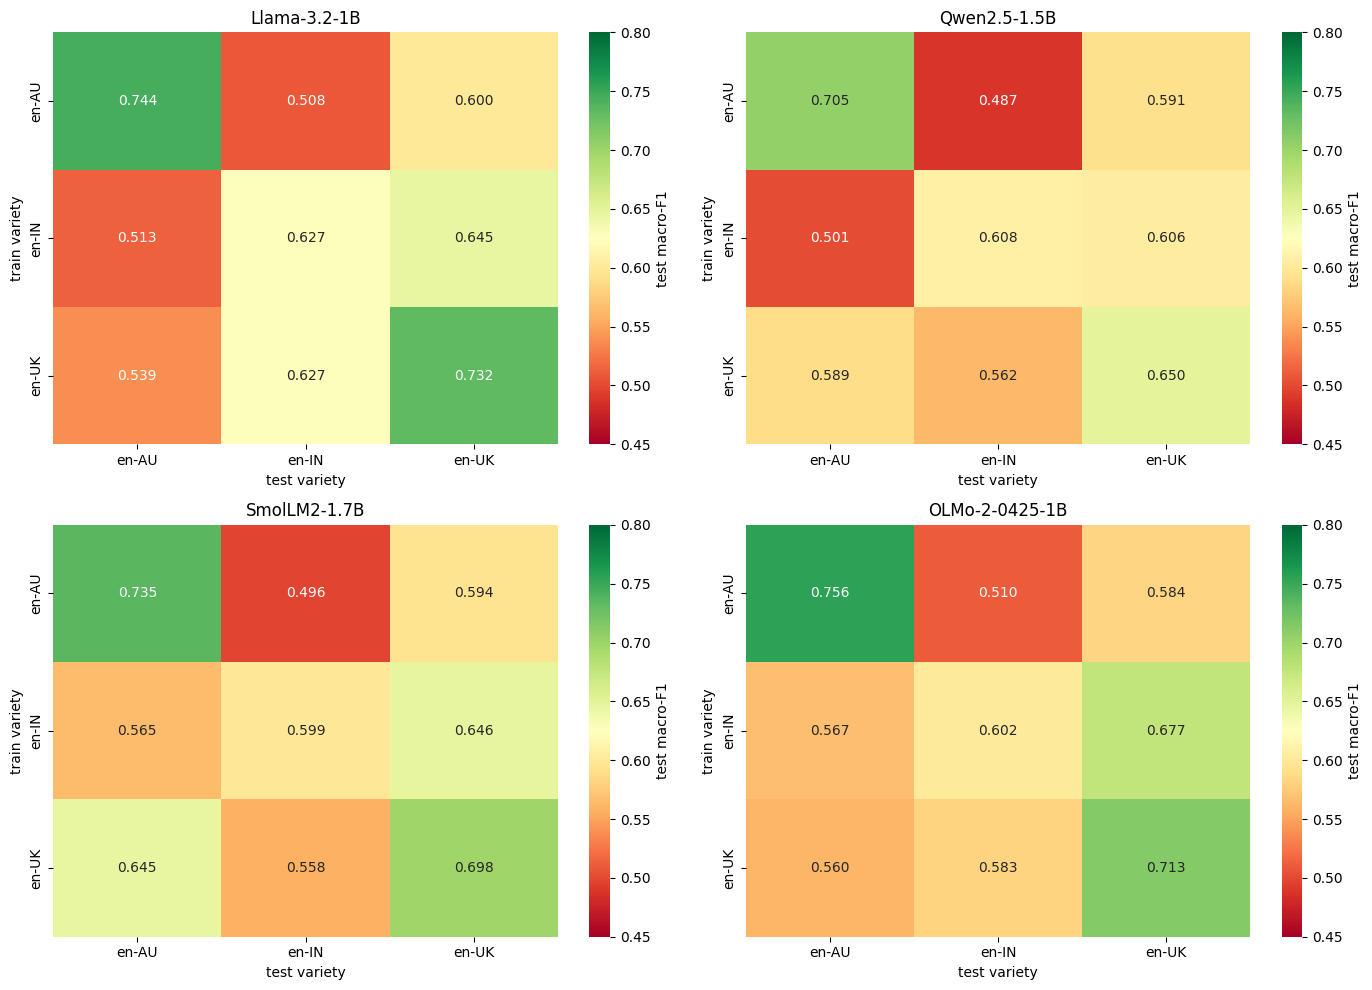

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, base_short in zip(axes.flat, BASES):
    sub = df_test[df_test['base_short'] == base_short]
    mat = sub.pivot_table(index='train_var', columns='test_var', values='macro_f1', aggfunc='mean')
    sns.heatmap(mat, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.45, vmax=0.80, ax=ax,
                cbar_kws={'label': 'test macro-F1'})
    ax.set_title(base_short)
    ax.set_xlabel('test variety')
    ax.set_ylabel('train variety')
plt.tight_layout()
plt.savefig('headline_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

Each panel is one base model. Rows are training variety, columns are test variety, and the colour shows the mean test macro-F1 across 3 seeds. Same-variety scores (diagonals) are stronger than cross-variety transfer.

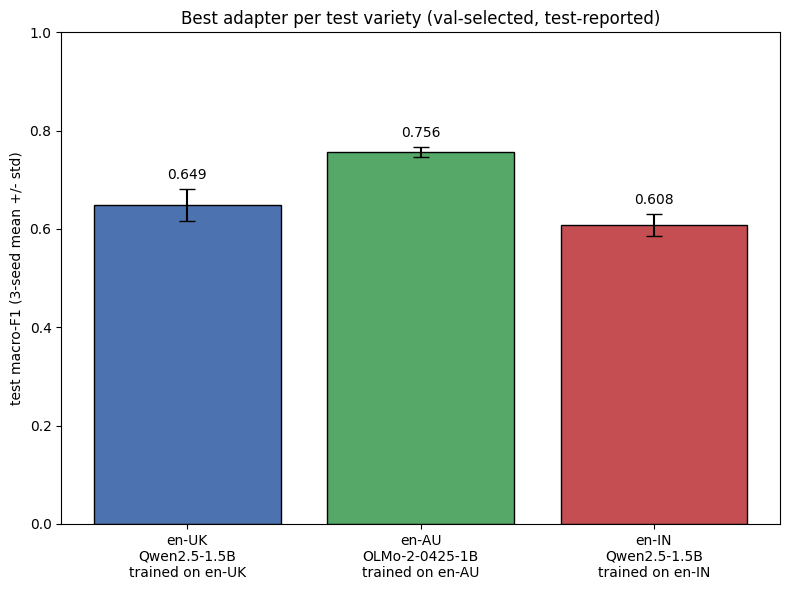

In [6]:
labels = list(VARIETIES)
means = [best[v]['test_mean_macro_f1'] for v in labels]
stds = [best[v]['test_std_macro_f1'] for v in labels]
tags = [f"{v}\n{best[v]['base_short']}\ntrained on {best[v]['train_var']}" for v in labels]

fig, ax = plt.subplots(figsize=(8, 6))
x = np.arange(len(labels))
ax.bar(x, means, yerr=stds, capsize=6, color=['#4c72b0', '#55a868', '#c44e52'], edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(tags)
ax.set_ylabel('test macro-F1 (3-seed mean +/- std)')
ax.set_title('Best adapter per test variety (val-selected, test-reported)')
ax.set_ylim(0, 1)
for i, m in enumerate(means):
    ax.text(i, m + stds[i] + 0.02, f'{m:.3f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('best_per_variety_bar.png', dpi=150, bbox_inches='tight')
plt.show()

Best adapter per test variety, val-selected and test-reported. The error bars are the 3-seed standard deviation. en-AU is easier than en-UK and en-IN because sarcasm appears more often in its training data.

## Confusion matrices

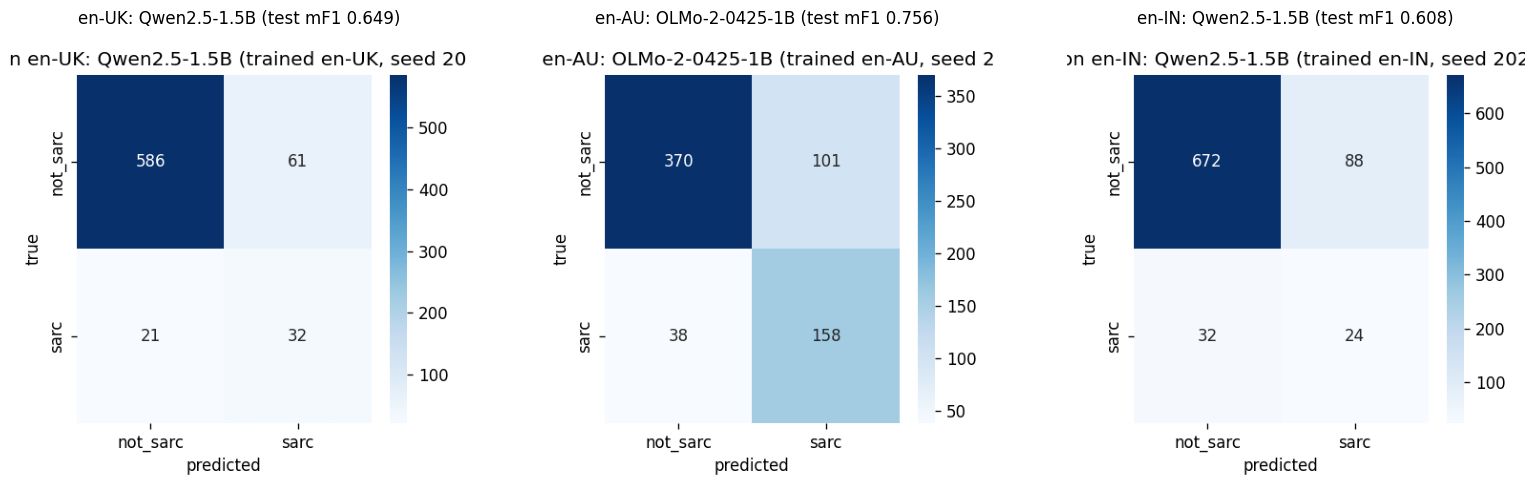

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, v in zip(axes, VARIETIES):
    p = EVAL_ROOT / 'confusion_matrices' / f'best_on_{v}.png'
    img = plt.imread(str(p))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"{v}: {best[v]['base_short']} (test mF1 {best[v]['test_mean_macro_f1']:.3f})")
plt.tight_layout()
plt.savefig('confusion_matrices_side_by_side.png', dpi=150, bbox_inches='tight')
plt.show()

Confusion matrices for each variety's val-selected best adapter, on the test split. The model handles non-sarcastic examples well; recall on the sarcastic class is lower for en-UK and en-IN because that class is rare in their training data.

## Misclassified examples preview

In [8]:
errors_csv = EVAL_ROOT / 'errors_for_q4' / 'SmolLM2-1.7B_en-UK_seed2024_misclassified.csv'
err_df = pd.read_csv(errors_csv)
print(f"{len(err_df)} misclassified test examples (sampled from total errors of the overall val-best adapter)")
err_df.head(15)

40 misclassified test examples (sampled from total errors of the overall val-best adapter)


,text,true_label,predicted_label,variety,base_model,training_variety,seed
0,That might cause a succesionary crisis.,0,1,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
1,Kannadigas say they are proud Indians as well ...,1,0,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
2,Australia doesn't really have crack.,0,1,en-AU,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
3,I love super nintendo chalmers!,0,1,en-UK,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
4,Iss clown ko andar daalo.,0,1,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
5,Ordered a Szechuan I got was chicken & carrot ...,1,0,en-AU,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
6,Just a rivalry between 2 criminals or maybe a ...,0,1,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
7,"Perfectly curated ""story"" to seem more ""relata...",1,0,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
8,"In a room full of idiots and wise men, the idi...",0,1,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024
9,I can see people buying it for kinky reasons only,0,1,en-IN,HuggingFaceTB/SmolLM2-1.7B,en-UK,2024


## Inference function demo

In [9]:
sys.path.insert(0, str(Path('.').resolve()))
from q5_2_inference import load as load_model, predict

DEMO = [
    ('en-UK', 'Qwen/Qwen2.5-1.5B', 'berkinksk/besstie-sarcasm-en-UK-Qwen2.5-1.5B-seed2024',
     "The new exhibition at the British Museum is genuinely worth visiting this weekend.",
     "Oh fantastic, another delayed train at Reading. Just what I needed today."),
    ('en-AU', 'allenai/OLMo-2-0425-1B', 'berkinksk/besstie-sarcasm-en-AU-OLMo-2-0425-1B-seed2024',
     "Sydney harbour at sunset is one of the best views in the world.",
     "Mate, that footy match was riveting. Best ninety minutes of my life."),
    ('en-IN', 'Qwen/Qwen2.5-1.5B', 'berkinksk/besstie-sarcasm-en-IN-Qwen2.5-1.5B-seed2024',
     "Bangalore weather has been quite pleasant this week.",
     "Such a wonderful service from the railways yesterday. Only 4 hours late."),
]

label_map = {0: 'not_sarcastic', 1: 'sarcastic'}
for variety, base_id, adapter_repo, plain_text, sarc_text in DEMO:
    tok, model = load_model(base_id, adapter_repo)
    for text in (plain_text, sarc_text):
        pred = predict(tok, model, text)
        print(f"{variety}: {text}")
        print(f"  prediction: {label_map[pred]}")
    print()
    del tok, model
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


en-UK: The new exhibition at the British Museum is genuinely worth visiting this weekend.
  prediction: not_sarcastic
en-UK: Oh fantastic, another delayed train at Reading. Just what I needed today.
  prediction: not_sarcastic



Loading weights:   0%|          | 0/178 [00:00<?, ?it/s]

[transformers] Olmo2ForSequenceClassification LOAD REPORT from: allenai/OLMo-2-0425-1B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


en-AU: Sydney harbour at sunset is one of the best views in the world.
  prediction: not_sarcastic
en-AU: Mate, that footy match was riveting. Best ninety minutes of my life.
  prediction: sarcastic



Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


en-IN: Bangalore weather has been quite pleasant this week.
  prediction: not_sarcastic
en-IN: Such a wonderful service from the railways yesterday. Only 4 hours late.
  prediction: not_sarcastic

